# Part 3: Question 2, Association Rules for Early Readmission

**Data science project: Predicting 30-Day Hospital Readmission for Patients with Diabetes**

**Name:** Bernard Issifu

**Question 2.** Which combinations of patient characteristics and treatments are associated with early
readmission?

This notebook uses association rule mining on the cleaned data from Part 1 (run
`01_data_preparation_eda.ipynb` first). The R version is `r/03_q2_association_rules.Rmd`.

In [1]:
# ---- Setup ----
import os
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv("../data/processed/diabetes_clean_python.csv", keep_default_na=False)
print(df.shape)

(69987, 47)


---
# 1. Approach

Question 1 showed *which single factors* predict readmission. Association rules look instead for
*combinations* of characteristics that occur together with readmission, and state them as readable
rules such as {two or more prior stays, HbA1c not tested} → {readmitted within 30 days}.

**Transactions.** Each patient becomes one "basket" of 16 items, one per attribute. Numeric features are
discretized into a few clinically sensible bins (for example length of stay 1–3, 4–7 or 8+ days), because
Apriori works on categorical items.

**Measures.** For a rule A → B:

- **support** = share of all patients who have both A and B;
- **confidence** = share of patients with A who also have B, here the readmission rate within group A;
- **lift** = confidence ÷ overall rate of B. A lift of 2 means patients with A are readmitted twice as
  often as average (8.98%); a lift below 1 means less often.

**Settings.** Apriori with **minimum support 0.5%** (at least 350 patients, so each rule rests on a
sizeable group) and at most 4 items per itemset. Only rules whose right-hand side is
`readmit_30=yes` are kept. Rules with **lift ≥ 1.5** (a readmission rate at least 50% above average)
describe higher-risk groups; rules with **lift ≤ 0.67** (at least a third below average) describe
lower-risk groups. The low-risk cut-off is less extreme because, with a 9% base rate, a group with a
very low readmission rate contains few readmitted patients, so its itemset rarely reaches the minimum
support; the lowest lift found is about 0.56.

**Redundancy.** Many rules just add an item to a shorter rule without changing its confidence. A rule
is kept only if its confidence is higher (for risk rules) or lower (for low-risk rules) than that of
every shorter rule contained in it.

In [2]:
items = pd.DataFrame(index=df.index)
items["age"] = pd.cut(df["age_years"], [0, 60, 80, 200], right=False,
                      labels=["<60", "60-79", "80+"]).astype(str)
items["gender"] = df["gender"]
items["admission"] = df["admission_type"]
items["source"] = df["admission_source"]
items["discharge"] = df["discharge_to"]
items["diag1"] = df["diag1_group"]
items["stay"] = pd.cut(df["time_in_hospital"], [0, 4, 8, 99], right=False,
                       labels=["1-3 days", "4-7 days", "8+ days"]).astype(str)
items["prior_inpatient"] = pd.cut(df["number_inpatient"], [-1, 0, 1, 999],
                                  labels=["0", "1", "2+"]).astype(str)
items["prior_emergency"] = np.where(df["number_emergency"] > 0, "1+", "0")
items["diagnoses"] = pd.cut(df["number_diagnoses"], [0, 7, 9, 99], right=False,
                            labels=["<7", "7-8", "9+"]).astype(str)
items["medications"] = pd.cut(df["num_medications"], [0, 11, 21, 999], right=False,
                              labels=["<11", "11-20", "21+"]).astype(str)
items["A1C"] = df["A1Cresult"].replace({">7": "high", ">8": "high", "None": "not tested",
                                        "Norm": "normal"})
items["insulin"] = np.where(df["insulin"] == "No", "no", "yes")
items["med_change"] = np.where(df["change"] == "Ch", "yes", "no")
items["diabetes_med"] = df["diabetesMed"].str.lower()
items["readmit_30"] = np.where(df["readmit_30"] == 1, "yes", "no")

# One-hot "basket" matrix: one True/False column per item, e.g. 'discharge=Home'
basket = pd.get_dummies(items, prefix_sep="=").astype(bool)
print(f"{basket.shape[0]:,} transactions, {basket.shape[1]} distinct items")
basket.mean().sort_values(ascending=False).round(3).head(10)

69,987 transactions, 53 distinct items


prior_emergency=0        0.927
readmit_30=no            0.910
prior_inpatient=0        0.883
A1C=not tested           0.816
diabetes_med=yes         0.762
discharge=Home           0.633
med_change=no            0.550
source=Emergency room    0.533
gender=Female            0.532
insulin=yes              0.510
dtype: float64

---
# 2. Mining the rules

In [3]:
frequent = apriori(basket, min_support=0.005, max_len=4, use_colnames=True, low_memory=True)
print(f"Frequent itemsets (support >= 0.5%): {len(frequent):,}")

rules = association_rules(frequent, metric="confidence", min_threshold=0.0)
target = frozenset({"readmit_30=yes"})
rules = rules[rules["consequents"] == target].copy()
base_rate = basket["readmit_30=yes"].mean()
print(f"Rules with consequent readmit_30=yes: {len(rules):,}  (base rate {base_rate:.2%})")

Frequent itemsets (support >= 0.5%): 73,622


Rules with consequent readmit_30=yes: 2,811  (base rate 8.98%)


In [4]:
# Confidence of every rule, looked up by its antecedent, plus the base rate for an empty antecedent
conf = dict(zip(rules["antecedents"], rules["confidence"]))
conf[frozenset()] = base_rate

def best_subset_conf(ante, higher):
    """Highest (or lowest) confidence among all proper subsets of the antecedent."""
    subs = [conf[frozenset(s)] for k in range(len(ante)) for s in combinations(ante, k)
            if frozenset(s) in conf]
    return max(subs) if higher else min(subs)

def tidy(r):
    out = r.copy()
    out["rule"] = out["antecedents"].apply(lambda a: "{" + ", ".join(sorted(a)) + "}")
    out["patients"] = (out["antecedent support"] * len(basket)).round().astype(int)
    return out[["rule", "patients", "support", "confidence", "lift"]].round(3)

high = rules[rules["lift"] >= 1.5]
keep = np.array([c > best_subset_conf(a, True) for a, c in zip(high["antecedents"], high["confidence"])],
                dtype=bool)
high = high[keep]
high = tidy(high.sort_values("lift", ascending=False))

low = rules[rules["lift"] <= 0.67]
keep = np.array([c < best_subset_conf(a, False) for a, c in zip(low["antecedents"], low["confidence"])],
                dtype=bool)
low = low[keep]
low = tidy(low.sort_values("lift"))

print(f"Higher-risk rules (lift >= 1.5): {len(high)} non-redundant, "
      f"from {int((rules['lift'] >= 1.5).sum())}")
print(f"Lower-risk rules (lift <= 0.67): {len(low)} non-redundant, "
      f"from {int((rules['lift'] <= 0.67).sum())}")

Higher-risk rules (lift >= 1.5): 77 non-redundant, from 172
Lower-risk rules (lift <= 0.67): 65 non-redundant, from 74


## 2.1 Higher-risk combinations

In [5]:
high.head(15).reset_index(drop=True)

,rule,patients,support,confidence,lift
0,"{A1C=not tested, prior_inpatient=2+}",2077,0.007,0.221,2.456
1,{prior_inpatient=2+},2397,0.007,0.215,2.392
2,"{diabetes_med=yes, diagnoses=<7, discharge=Care facility}",1942,0.005,0.191,2.122
3,"{diabetes_med=yes, diag1=Circulatory, discharge=Care facility}",2249,0.006,0.185,2.060
4,"{admission=Emergency, age=60-79, discharge=Care facility}",2842,0.007,0.182,2.030
5,"{age=60-79, discharge=Care facility, source=Emergency room}",2883,0.008,0.182,2.028
6,"{age=60-79, discharge=Care facility, medications=11-20}",2662,0.007,0.180,2.008
7,"{age=60-79, diabetes_med=yes, discharge=Care facility}",4394,0.011,0.179,1.992
8,"{diag1=Circulatory, discharge=Care facility, prior_emergency=0}",2642,0.007,0.179,1.989
9,"{diagnoses=<7, discharge=Care facility, prior_emergency=0}",2413,0.006,0.178,1.984


## 2.2 Lower-risk combinations

In [6]:
low.head(10).reset_index(drop=True)

,rule,patients,support,confidence,lift
0,"{age=<60, medications=<11, prior_inpatient=0}",7244,0.005,0.050,0.556
1,"{age=<60, diagnoses=<7, prior_inpatient=0}",9940,0.007,0.050,0.559
2,"{diabetes_med=no, discharge=Home, prior_inpatient=0}",9633,0.007,0.051,0.566
3,"{age=<60, diagnoses=<7, stay=1-3 days}",7205,0.005,0.051,0.570
4,"{age=<60, diagnoses=<7, discharge=Home}",8862,0.006,0.051,0.570
5,"{diagnoses=<7, discharge=Home, prior_inpatient=0}",16257,0.012,0.053,0.586
6,"{diagnoses=<7, discharge=Home, medications=<11}",7902,0.006,0.053,0.586
7,"{age=<60, discharge=Home, prior_inpatient=0}",16636,0.013,0.053,0.586
8,"{age=<60, discharge=Home, insulin=no}",8135,0.006,0.053,0.593
9,"{age=<60, medications=<11, prior_emergency=0}",7200,0.005,0.053,0.594


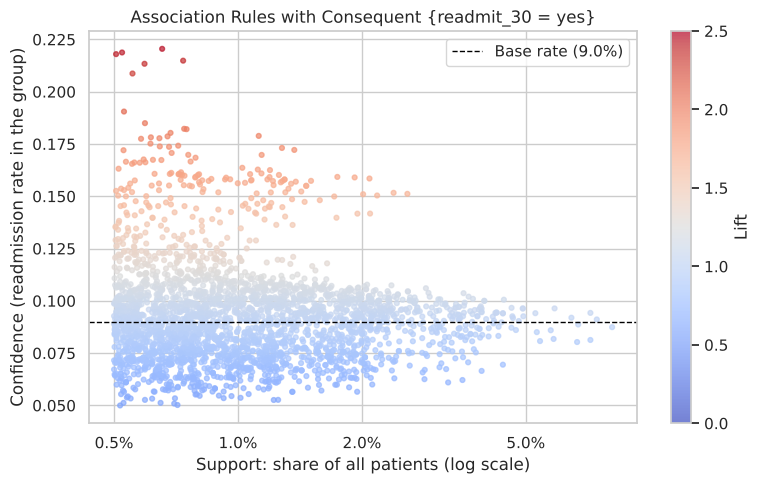

In [7]:
# Support vs confidence for all readmission rules, coloured by lift
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="coolwarm",
                s=12, alpha=0.7, vmin=0, vmax=2.5)
ax.axhline(base_rate, color="black", ls="--", lw=1, label=f"Base rate ({base_rate:.1%})")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([0.005, 0.01, 0.02, 0.05])
ax.set_title("Association Rules with Consequent {readmit_30 = yes}")
ax.set_xlabel("Support: share of all patients (log scale)")
ax.set_ylabel("Confidence (readmission rate in the group)")
fig.colorbar(sc, label="Lift")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_rules_scatter.png", dpi=150)
plt.show()

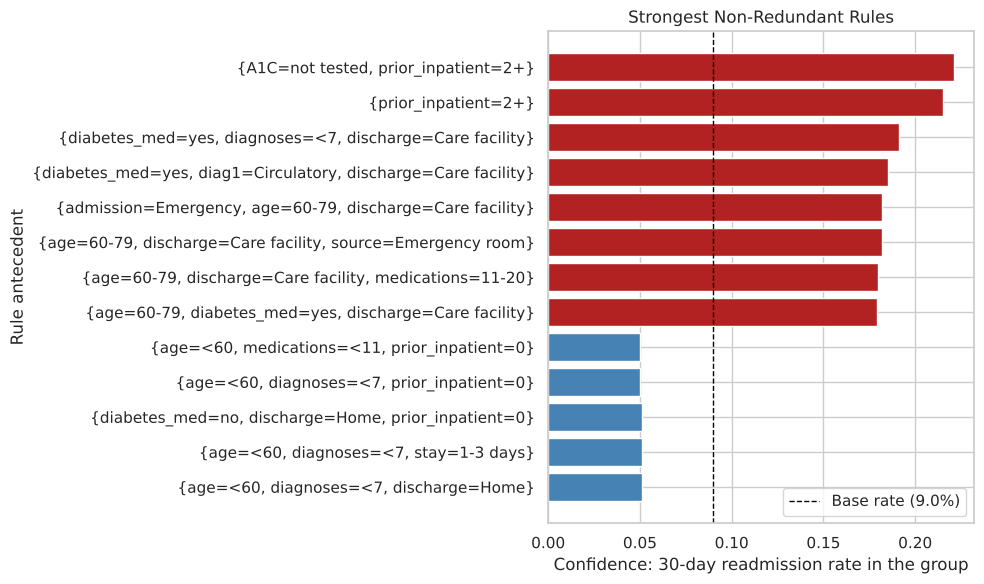

In [8]:
# Readmission rate (confidence) of the top non-redundant rules on each side
show = pd.concat([high.head(8).assign(kind="Higher risk"), low.head(5).assign(kind="Lower risk")])
fig, ax = plt.subplots(figsize=(10, 6))
colors = show["kind"].map({"Higher risk": "firebrick", "Lower risk": "steelblue"})
ax.barh(show["rule"][::-1], show["confidence"][::-1], color=colors[::-1])
ax.axvline(base_rate, color="black", ls="--", lw=1, label=f"Base rate ({base_rate:.1%})")
ax.set_title("Strongest Non-Redundant Rules")
ax.set_xlabel("Confidence: 30-day readmission rate in the group")
ax.set_ylabel("Rule antecedent")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_top_rules.png", dpi=150)
plt.show()

In [9]:
high.to_csv(f"{FIG_DIR}/q2_high_risk_rules_python.csv", index=False)
low.to_csv(f"{FIG_DIR}/q2_low_risk_rules_python.csv", index=False)

---
# 3. Discussion

**Higher-risk combinations.** The 77 non-redundant higher-risk rules fall into two families:

1. **Repeated hospital use.** Patients with **two or more inpatient stays in the previous year** (2,397
   patients) are readmitted within 30 days at **21.5%**, 2.4 times the average. Adding *HbA1c not
   tested* gives the strongest rule overall: 22.1% (lift 2.46, 2,077 patients). The added item changes
   the rate only slightly, so the prior stays carry almost all of the risk.
2. **Discharge to a care facility**, combined with other markers of a serious stay. Care-facility
   patients aged 60–79 who were admitted as emergencies, or whose primary diagnosis was circulatory,
   are readmitted at 17–19% (lift about 2.0, groups of 2,200–4,400 patients).

Some rules pair care-facility discharge with *fewer than 7 recorded diagnoses* (19.1%, lift 2.12). That
is counter-intuitive, since fewer diagnoses usually means a less complex patient. It may reflect how
diagnoses were recorded for transferred patients rather than lower complexity, and it is a reminder
that association rules describe co-occurrence, not cause.

**Lower-risk combinations.** The lowest readmission rates, about **5%** (lift 0.56–0.59, about 40%
below average), belong to large groups of **younger patients (under 60) with no prior inpatient stay**,
especially when they are discharged home and have few diagnoses or medications. For example, the
16,636 patients under 60 who were discharged home with no prior stay are readmitted at 5.3%.

**How this complements Question 1.** The rules confirm the two strongest predictors from the
classifiers, prior inpatient visits and discharge destination, and turn them into concrete groups that a
hospital could act on: a patient with two or more stays in the past year has better than a 1-in-5
chance of returning within a month. The rules add the context the single-factor view misses, for
example that care-facility risk is concentrated among older and emergency patients.

**Limitations.** The rules depend on the chosen bins and thresholds. The 0.5% minimum support hides
small but extreme groups; for example, patients with three or more prior stays (26.5%, see Part 1)
appear only within the "2+" item. Rules are descriptive and cannot separate the effect of each item from
the others the way the logistic regression does.